<center><h1>Zhu_Lingfei_HW6</h1></center>

Name: Zhu Lingfei
<br>
Github Username: youth0505
<br>
USC ID: 8599420339

## 1. Tree-Based Methods

Import packages

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score,
    accuracy_score
)
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from imblearn.ensemble import BalancedRandomForestClassifier

### (a) Download the APS Failure data

In [2]:
train = pd.read_csv(
    "../data/aps_failure_training_set.csv",
    skiprows=20,
    na_values=["na"]
)

test = pd.read_csv(
    "../data/aps_failure_test_set.csv",
    skiprows=20,
    na_values=["na"]
)
print("Training set shape:", train.shape)
print("Test set shape:", test.shape)

print("\nTraining set:")
display(train.head())

print("\nTest set:")
display(test.head())

Training set shape: (60000, 171)
Test set shape: (16000, 171)

Training set:


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,...,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,...,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0



Test set:


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,60,0.0,20.0,12.0,0.0,0.0,0.0,0.0,0.0,...,1098.0,138.0,412.0,654.0,78.0,88.0,0.0,0.0,0.0,0.0
1,neg,82,0.0,68.0,40.0,0.0,0.0,0.0,0.0,0.0,...,1068.0,276.0,1620.0,116.0,86.0,462.0,0.0,0.0,0.0,0.0
2,neg,66002,2.0,212.0,112.0,0.0,0.0,0.0,0.0,0.0,...,495076.0,380368.0,440134.0,269556.0,1315022.0,153680.0,516.0,0.0,0.0,0.0
3,neg,59816,NaN,1010.0,936.0,0.0,0.0,0.0,0.0,0.0,...,540820.0,243270.0,483302.0,485332.0,431376.0,210074.0,281662.0,3232.0,0.0,0.0
4,neg,1814,NaN,156.0,140.0,0.0,0.0,0.0,0.0,0.0,...,7646.0,4144.0,18466.0,49782.0,3176.0,482.0,76.0,0.0,0.0,0.0


### (b) Data Preparation

#### (i) Research what types of techniques are usually used

Missing values are common in real-world datasets. Several techniques can be used to handle missing data:

Mean Imputation: Replace missing values with the mean of the corresponding feature. This method is simple but sensitive to outliers.

Median Imputation: Replace missing values with the median of the corresponding feature. It is more robust to outliers than mean imputation.

Mode Imputation: Replace missing values with the most frequently occurring value. It is commonly used for categorical features.

KNN Imputation: Estimate missing values based on the values of the nearest neighboring observations.

For this dataset, I choose Median Imputation because all 170 input features are numerical, and some features may contain extreme values. Compared with mean imputation, median imputation is less sensitive to outliers and provides a more robust estimate of missing values.

Therefore, I will use median imputation to handle missing values in the APS Failure dataset before proceeding with the subsequent analysis and model training.

In [3]:
X_train = train.drop(columns=['class'])
X_test = test.drop(columns=['class'])

y_train = train['class']
y_test = test['class']

X_train = X_train.fillna(X_train.median())
X_test = X_test.fillna(X_test.median())

print("Missing values in training set:", X_train.isnull().sum().sum())
print("Missing values in test set:", X_test.isnull().sum().sum())

Missing values in training set: 0
Missing values in test set: 0


#### (ii) Calculate the coefficient of variation

In [4]:
feature_mean = X_train.mean()
feature_std = X_train.std()

cv = feature_std / feature_mean

cv_summary = pd.DataFrame({
    'Mean': feature_mean,
    'Standard Deviation': feature_std,
    'CV': cv
})
top_features = cv.sort_values(ascending=False).head(int(np.floor(np.sqrt(170))))
display(cv_summary)
print("Number of features:", len(cv))
print("Number of invalid CV values:", cv.isin([np.inf, -np.inf]).sum() + cv.isna().sum())

,Mean,Standard Deviation,CV
aa_000,5.933650e+04,1.454301e+05,2.450938
ab_000,1.625000e-01,1.687318e+00,10.383494
ac_000,3.362258e+08,7.767625e+08,2.310241
ad_000,1.434383e+05,3.504525e+07,244.322816
ae_000,6.535000e+00,1.581479e+02,24.200137
...,...,...,...
ee_007,3.428586e+05,1.718666e+06,5.012754
ee_008,1.372212e+05,4.472145e+05,3.259079
ee_009,8.295099e+03,4.721249e+04,5.691612
ef_000,8.646667e-02,4.268570e+00,49.366659


Number of features: 170
Number of invalid CV values: 0


#### (iii) Plot a correlation matrix

          aa_000    ab_000    ac_000    ad_000    ae_000    af_000    ag_000  \
aa_000  1.000000  0.014085 -0.063876 -0.001590  0.043095  0.062855  0.018549   
ab_000  0.014085  1.000000 -0.002128 -0.000394  0.037572  0.053293 -0.000179   
ac_000 -0.063876 -0.002128  1.000000 -0.001765 -0.004250 -0.009480  0.017155   
ad_000 -0.001590 -0.000394 -0.001765  1.000000 -0.000168 -0.000209 -0.000043   
ae_000  0.043095  0.037572 -0.004250 -0.000168  1.000000  0.823123 -0.000445   
...          ...       ...       ...       ...       ...       ...       ...   
ee_007  0.603888  0.008520 -0.048648 -0.000801  0.035503  0.047858  0.000329   
ee_008  0.469836 -0.025599 -0.003714 -0.001235 -0.009632 -0.012347 -0.000787   
ee_009  0.247149 -0.016247  0.013764 -0.000716 -0.007218 -0.008996 -0.001209   
ef_000  0.012409  0.056271 -0.006262 -0.000082  0.070869  0.106312 -0.000078   
eg_000  0.024387  0.106360  0.014747 -0.000096  0.041725  0.060756  0.000236   

          ag_001    ag_002    ag_003  .

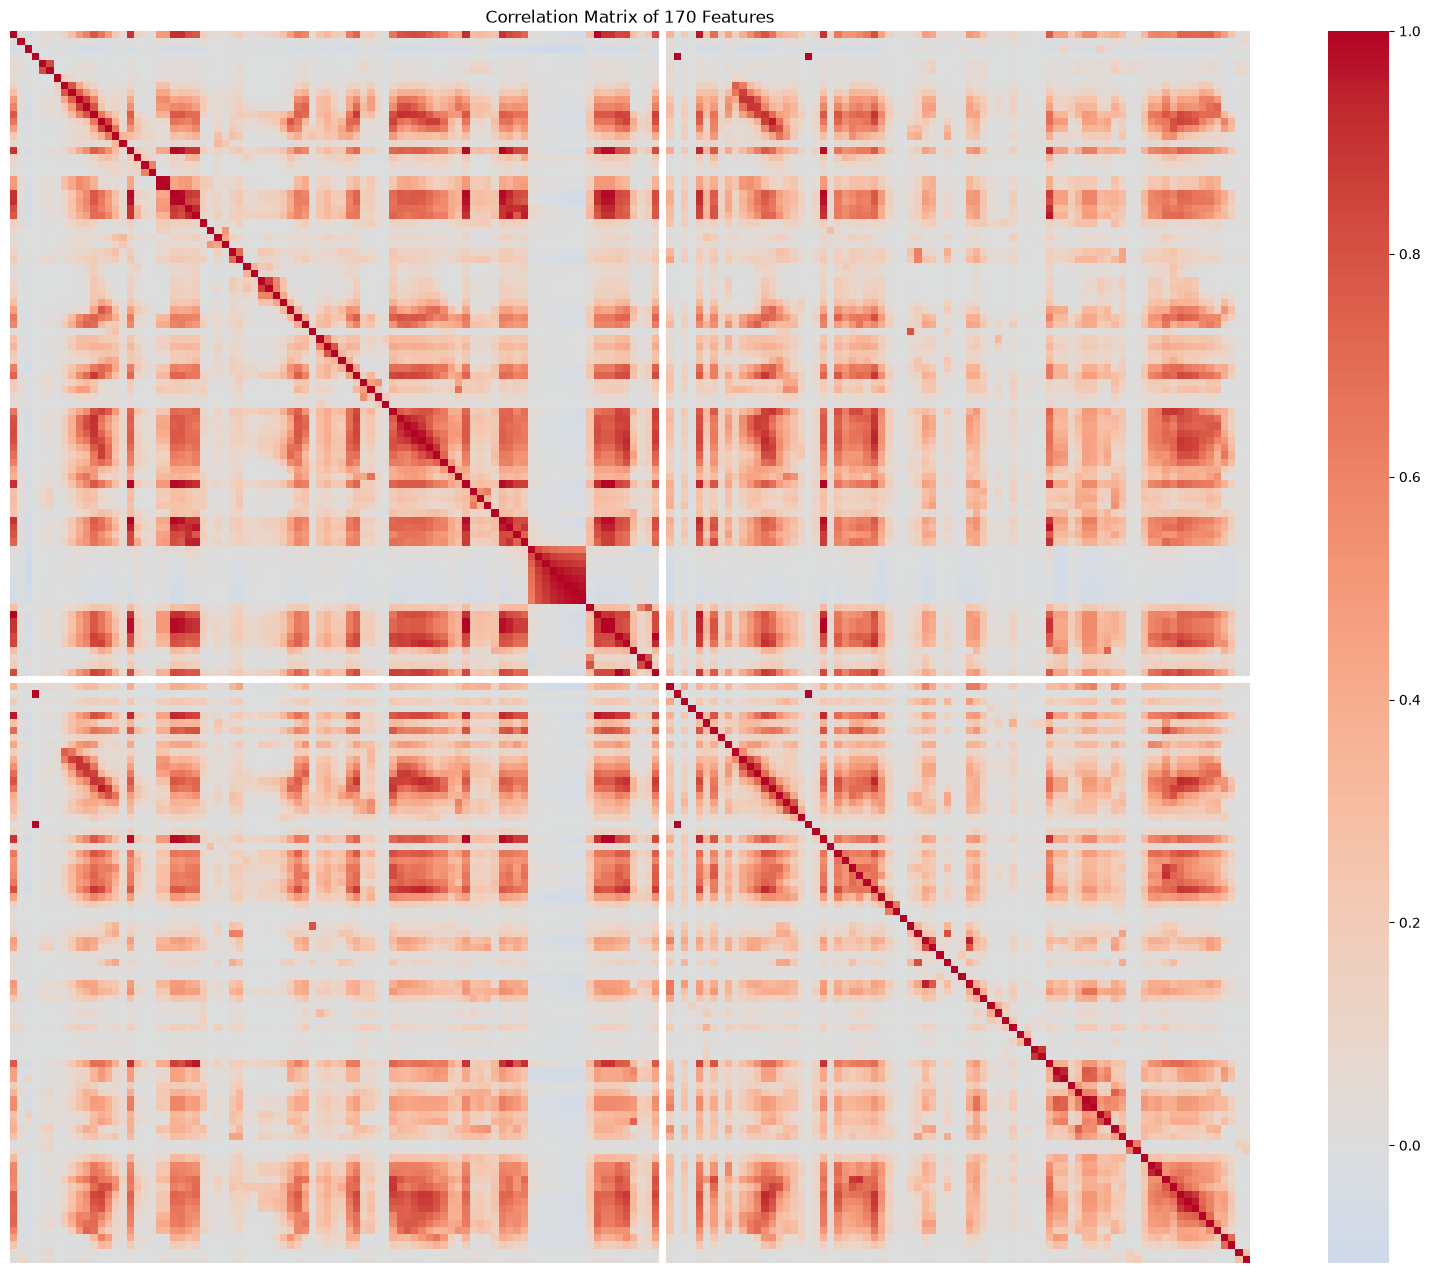

In [5]:
correlation_matrix = X_train.corr()
plt.figure(figsize=(20, 16))

sns.heatmap(
    correlation_matrix,
    cmap='coolwarm',
    center=0,
    xticklabels=False,
    yticklabels=False
)

plt.title("Correlation Matrix of 170 Features")
plt.show()

In [6]:
zero_variance = X_train.columns[
    X_train.std() == 0
]

print("Zero variance features:")
print(zero_variance.tolist())

Zero variance features:
['cd_000']


I calculated the Pearson correlation coefficients among all 170 numerical features and visualized them using a heatmap.

The correlation matrix shows that some groups of features have relatively strong positive correlations, while others have weak correlations.

The clustered red regions indicate that certain features tend to change together, suggesting potential relationships or redundancy among some features.

Overall, the heatmap provides an overview of the linear relationships between the features. However, correlation does not necessarily imply causation, and it does not directly indicate the predictive importance of a feature.

#### (iv) Make scatter plots and box plots

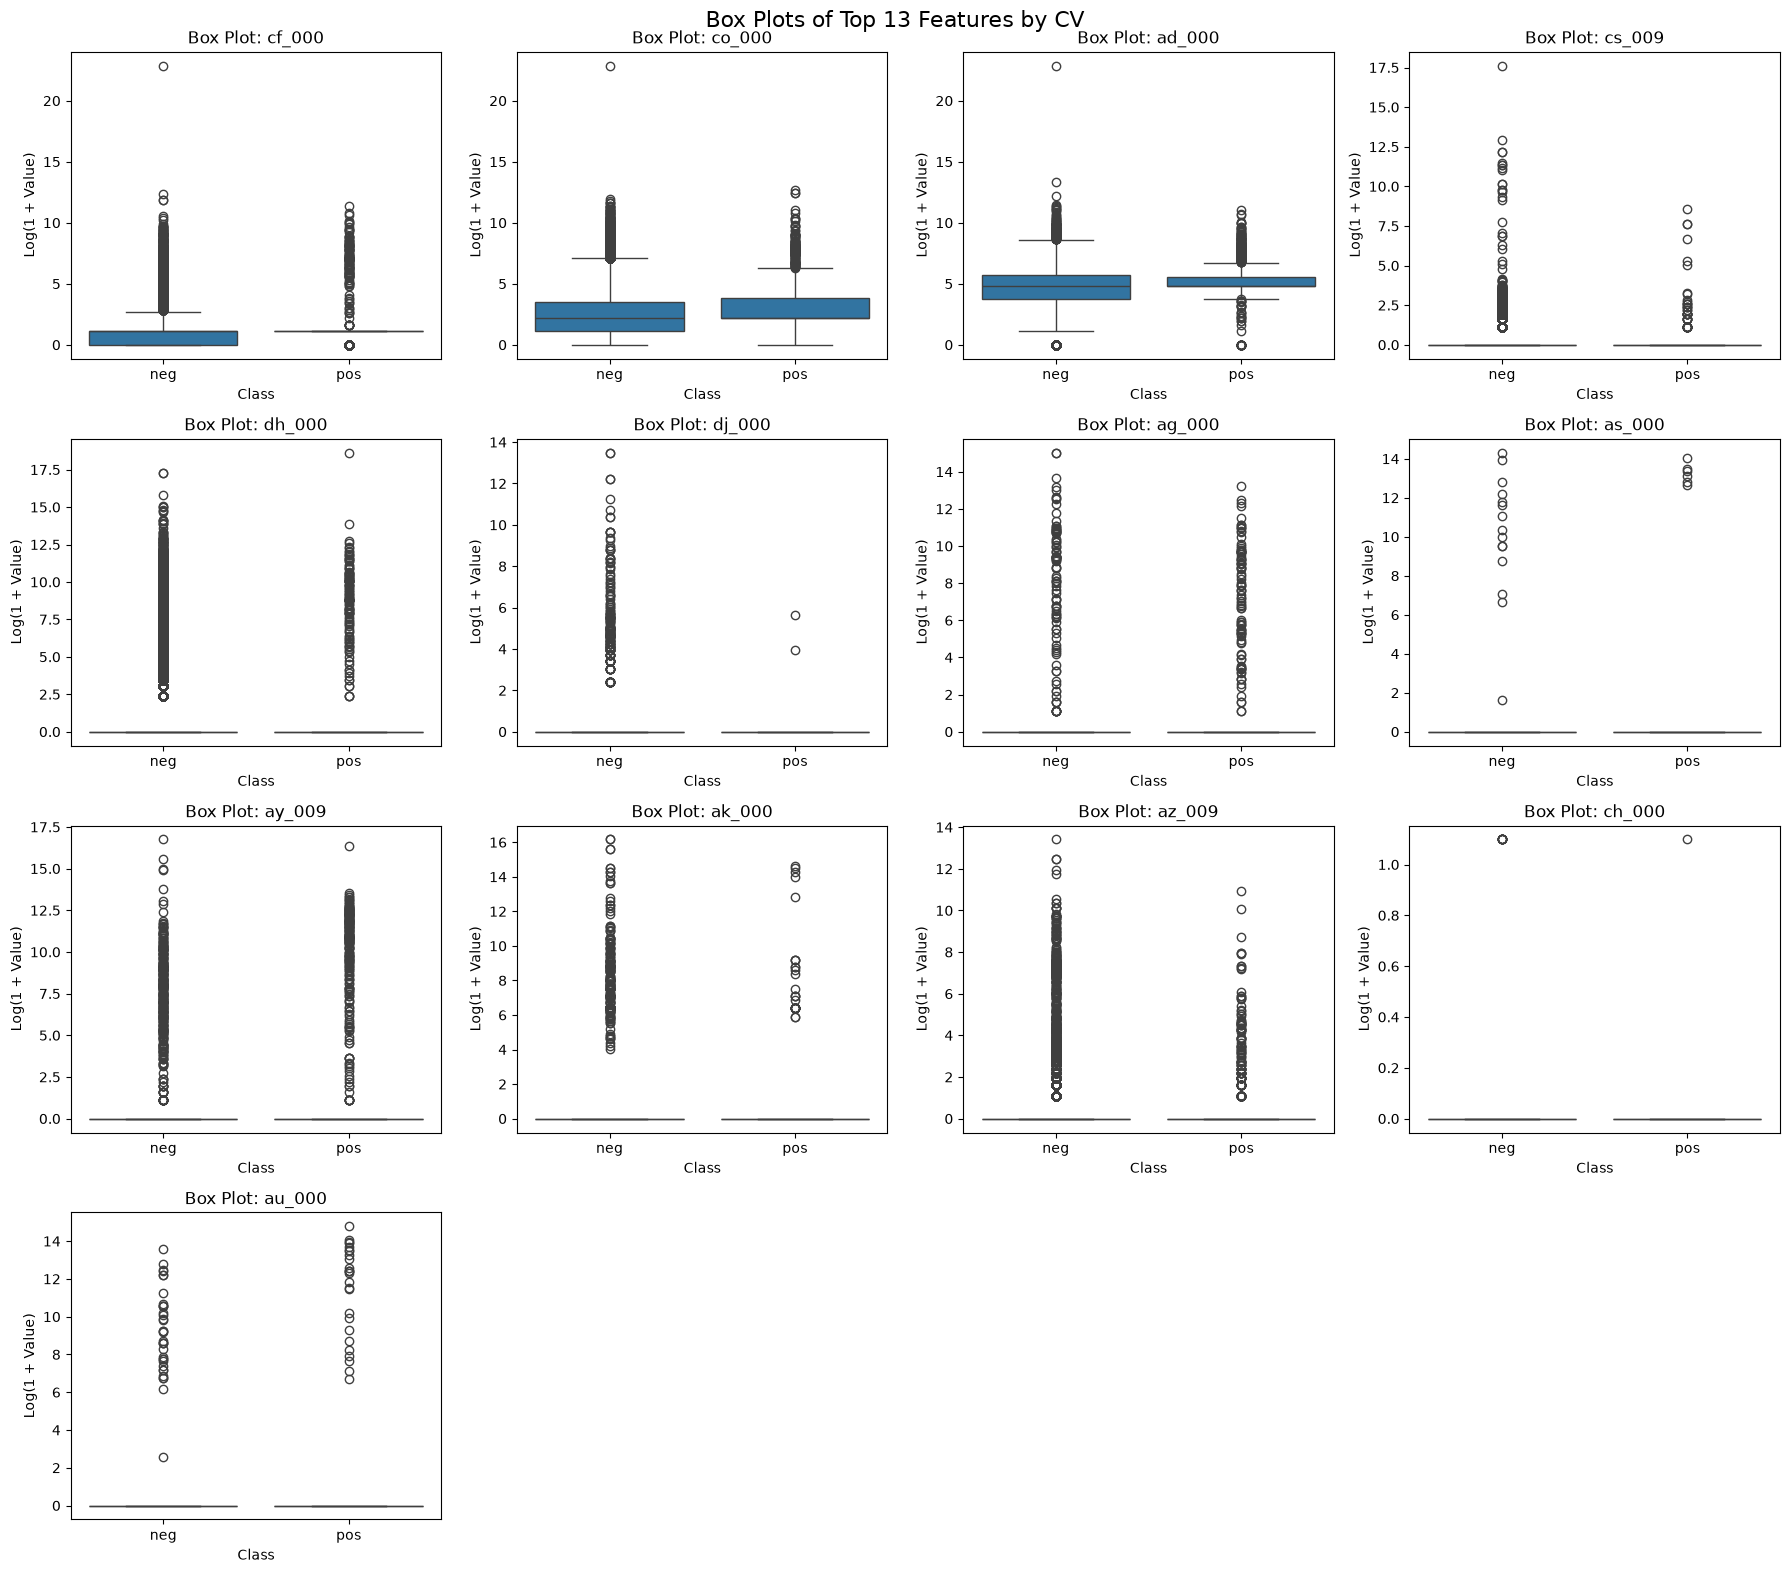

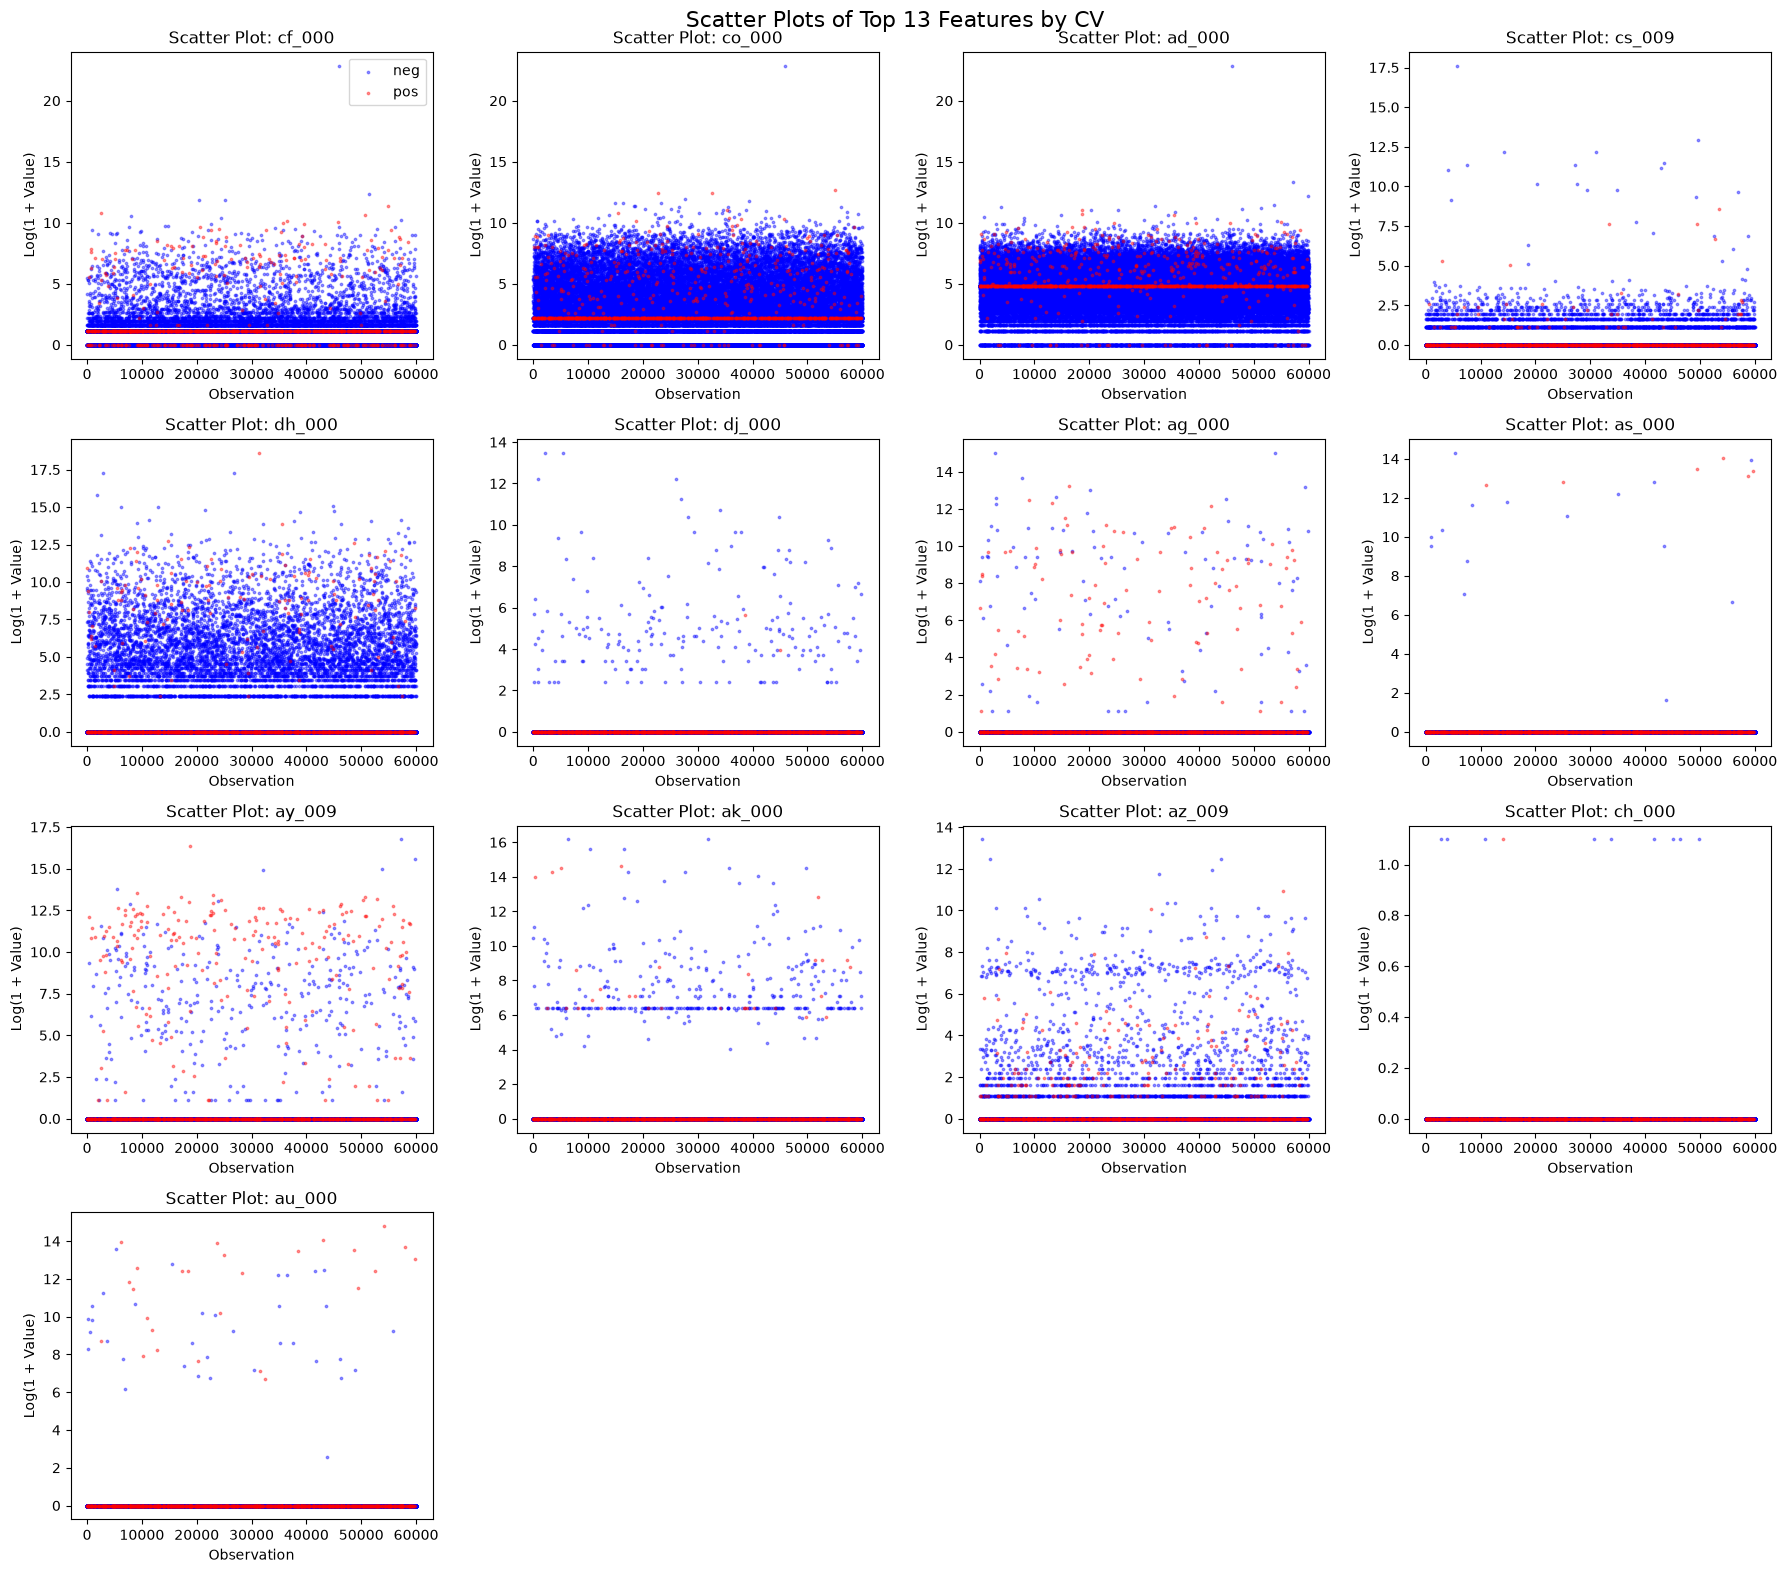

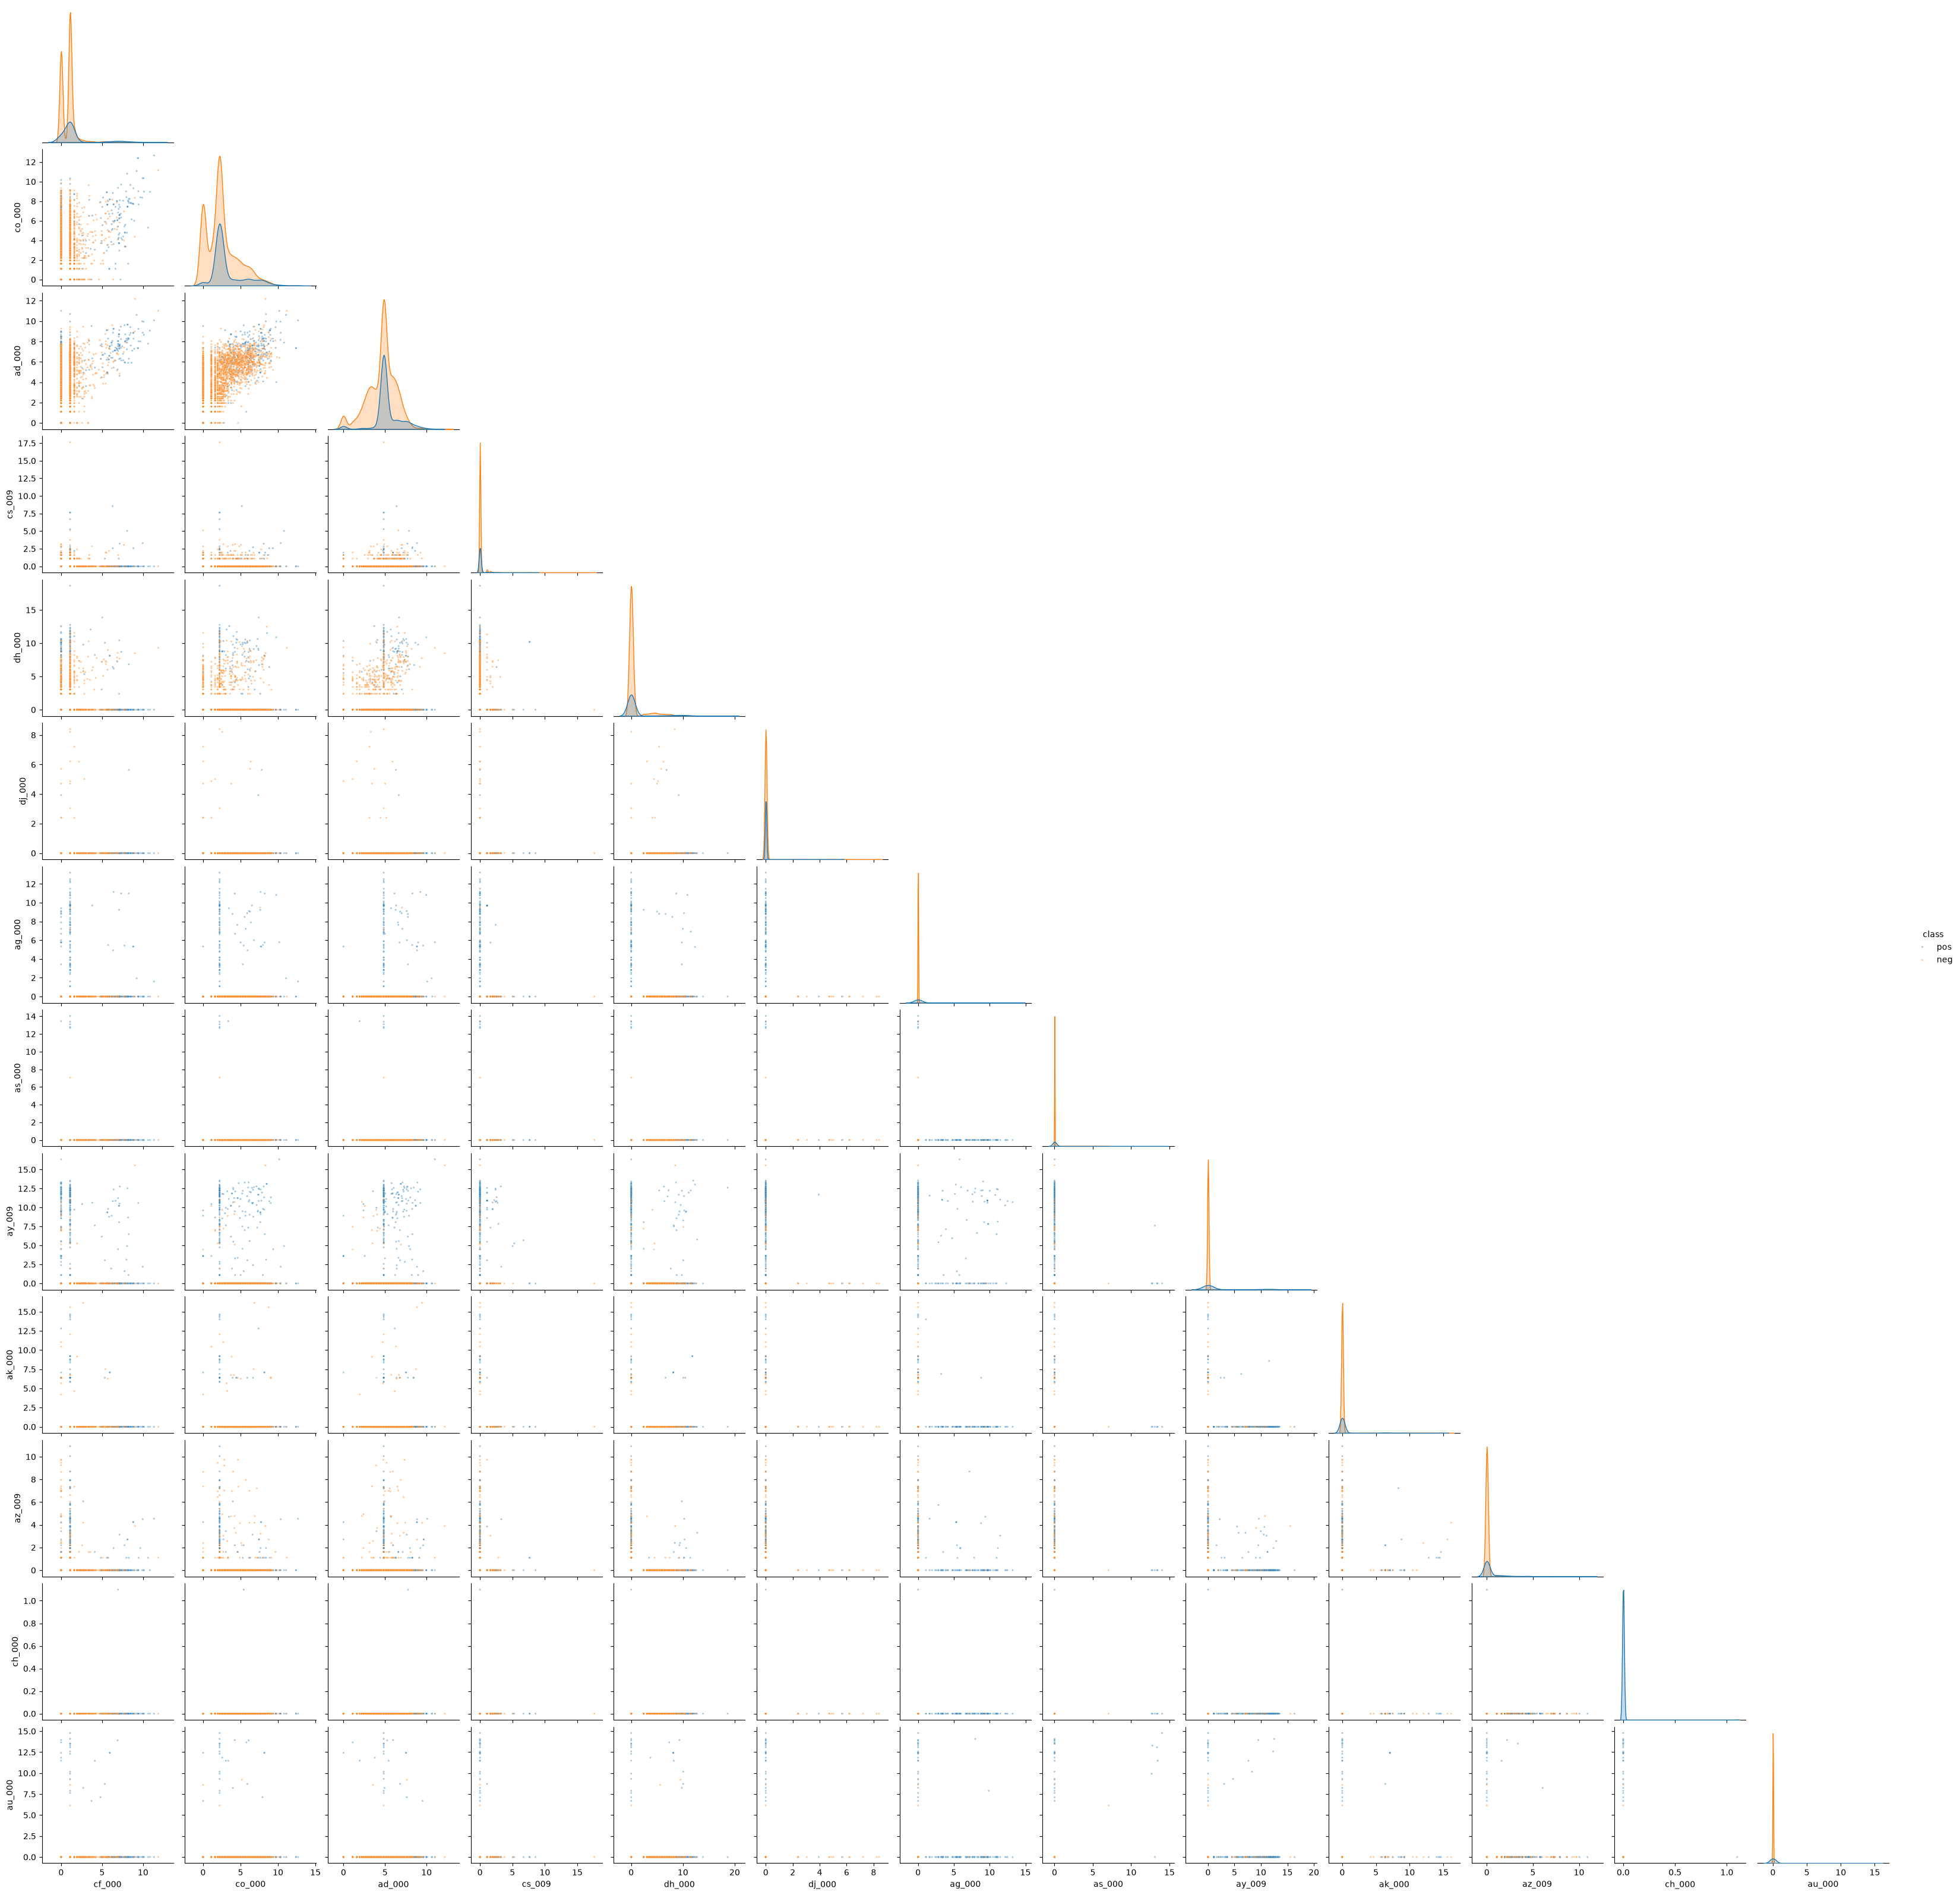

In [7]:
plot_data = X_train[top_features.index].copy()
plot_data['class'] = y_train

plot_features = np.log1p(plot_data[top_features.index])

plot_data_log = plot_features.copy()
plot_data_log['class'] = y_train

fig, axes = plt.subplots(4, 4, figsize=(18, 16))
axes = axes.flatten()

for i, feature in enumerate(top_features.index):

    sns.boxplot(
        data=plot_data_log,
        x='class',
        y=feature,
        showfliers=True,
        ax=axes[i]
    )

    axes[i].set_title(f'Box Plot: {feature}')
    axes[i].set_xlabel('Class')
    axes[i].set_ylabel('Log(1 + Value)')

for i in range(13, 16):
    axes[i].set_visible(False)

plt.suptitle('Box Plots of Top 13 Features by CV', fontsize=16)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(4, 4, figsize=(18, 16))
axes = axes.flatten()

for i, feature in enumerate(top_features.index):

    for label, color in [('neg', 'blue'), ('pos', 'red')]:

        mask = y_train == label

        axes[i].scatter(
            np.where(mask)[0],
            plot_features.loc[mask, feature],
            s=3,
            alpha=0.4,
            color=color,
            label=label
        )

    axes[i].set_title(f'Scatter Plot: {feature}')
    axes[i].set_xlabel('Observation')
    axes[i].set_ylabel('Log(1 + Value)')

    if i == 0:
        axes[i].legend()

for i in range(13, 16):
    axes[i].set_visible(False)

plt.suptitle('Scatter Plots of Top 13 Features by CV', fontsize=16)
plt.tight_layout()
plt.show()

sub = pd.concat([X_train[top_features.index], y_train], axis=1)
sub = pd.concat([sub[sub['class']=='pos'], sub[sub['class']=='neg'].sample(3000, random_state=0)])
sns.pairplot(np.log1p(sub[top_features.index]).assign(**{'class': sub['class']}),hue='class', plot_kws={'s': 5, 'alpha': .4}, corner=True)

The 13 features with the highest CV are listed above ($\lfloor\sqrt{170}\rfloor = 13$). I plotted them on a log(1+x) scale because most of them are zero-inflated with a few huge values.

Only cf_000, co_000 and ad_000 show a visible shift: the pos class sits higher in the box plots, and in the scatter matrix the pos points lean toward the upper right. The other ten features are almost all zeros plus scattered outliers, and the two classes look the same.

So no, the scatter plots alone cannot tell us which features matter. A high CV mostly reflects sparse counters with extreme values, and the pos class has only 1,000 points that are hidden behind the 59,000 neg points. Significance would need a test or a model-based importance measure.

#### (v) Is this data set imbalanced?

In [8]:
print("Training set class distribution:")
print(y_train.value_counts())

print("\nTest set class distribution:")
print(y_test.value_counts())

print("Training set percentage:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTest set percentage:")
print((y_test.value_counts(normalize=True) * 100).round(2))

Training set class distribution:
class
neg    59000
pos     1000
Name: count, dtype: int64

Test set class distribution:
class
neg    15625
pos      375
Name: count, dtype: int64
Training set percentage:
class
neg    98.33
pos     1.67
Name: proportion, dtype: float64

Test set percentage:
class
neg    97.66
pos     2.34
Name: proportion, dtype: float64


The dataset is highly imbalanced because the number of negative samples is significantly greater than the number of positive samples. In the training set, the ratio of negative to positive samples is 59:1.

This class imbalance may cause a classification model to favor the majority class (negative) and perform poorly in identifying the minority class (positive). Therefore, accuracy alone may not be a reliable evaluation metric. Metrics such as precision, recall, F1-score, and AUC should also be considered.

### (c) Train a random forest

Random Forest training completed!
Training predictions completed!
Test predictions completed!
Training Accuracy: 0.9999833333333333
Test Accuracy: 0.9924375
OOB Score: 0.9938333333333333
OOB Error: 0.006166666666666654


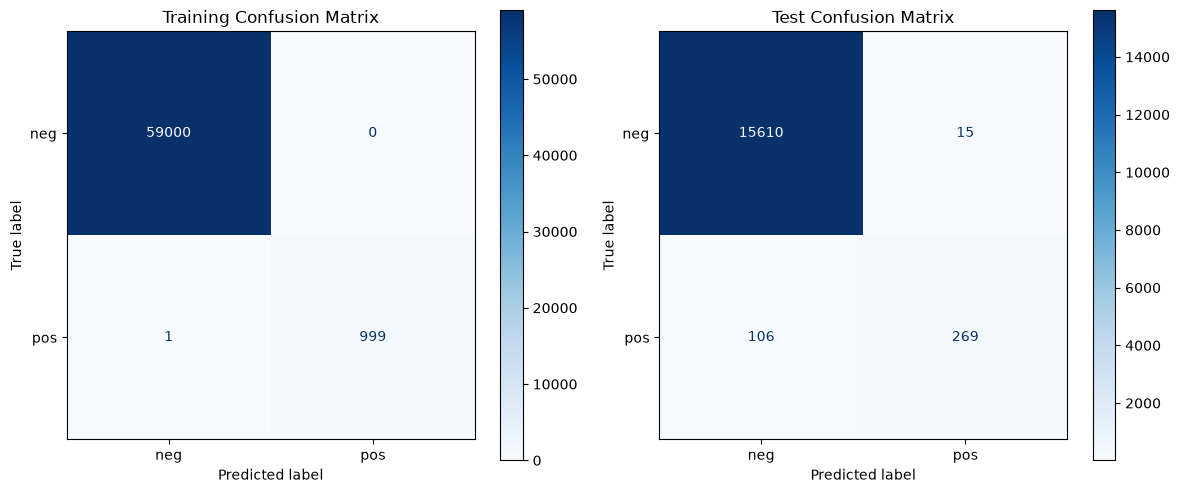

In [9]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    oob_score=True,
    bootstrap=True
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")
y_train_pred = rf_model.predict(X_train)
y_test_pred = rf_model.predict(X_test)

# Predict probabilities for positive class
y_train_prob = rf_model.predict_proba(X_train)[:, 1]
y_test_prob = rf_model.predict_proba(X_test)[:, 1]

print("Training predictions completed!")
print("Test predictions completed!")
print("Training Accuracy:", accuracy_score(y_train, y_train_pred))
print("Test Accuracy:", accuracy_score(y_test, y_test_pred))

print("OOB Score:", rf_model.oob_score_)
print("OOB Error:", 1 - rf_model.oob_score_)
# Calculate confusion matrices
cm_train = confusion_matrix(
    y_train,
    y_train_pred,
    labels=['neg', 'pos']
)

cm_test = confusion_matrix(
    y_test,
    y_test_pred,
    labels=['neg', 'pos']
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm_train,
    display_labels=['neg', 'pos']
).plot(ax=axes[0], cmap='Blues', values_format='d')

axes[0].set_title('Training Confusion Matrix')

ConfusionMatrixDisplay(
    confusion_matrix=cm_test,
    display_labels=['neg', 'pos']
).plot(ax=axes[1], cmap='Blues', values_format='d')

axes[1].set_title('Test Confusion Matrix')

plt.tight_layout()
plt.show()

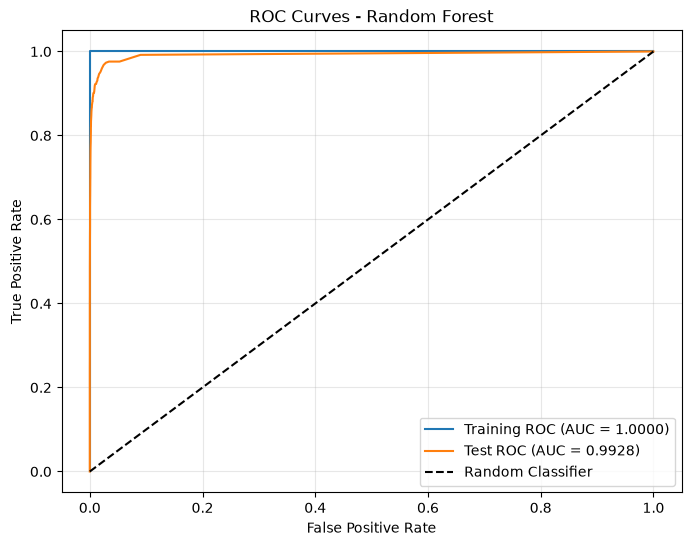

Training AUC: 1.0
Test AUC: 0.9927564799999999


In [10]:
fpr_train, tpr_train, _ = roc_curve(
    y_train, y_train_prob, pos_label='pos'
)

fpr_test, tpr_test, _ = roc_curve(
    y_test, y_test_prob, pos_label='pos'
)

auc_train = roc_auc_score(y_train, y_train_prob)
auc_test = roc_auc_score(y_test, y_test_prob)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_train, tpr_train,
    label=f'Training ROC (AUC = {auc_train:.4f})'
)

plt.plot(
    fpr_test, tpr_test,
    label=f'Test ROC (AUC = {auc_test:.4f})'
)

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves - Random Forest')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Training AUC:", auc_train)
print("Test AUC:", auc_test)

In [11]:
train_mr = 1 - accuracy_score(y_train, y_train_pred)
test_mr = 1 - accuracy_score(y_test, y_test_pred)

print("Training Misclassification Rate:", train_mr)
print("Test Misclassification Rate:", test_mr)

print("\nTraining Misclassification Rate (%):",
      train_mr * 100)

print("Test Misclassification Rate (%):",
      test_mr * 100)

Training Misclassification Rate: 1.666666666666483e-05
Test Misclassification Rate: 0.0075625000000000275

Training Misclassification Rate (%): 0.0016666666666664831
Test Misclassification Rate (%): 0.7562500000000028


In [12]:
train_error = 1 - accuracy_score(y_train, y_train_pred)
test_error = 1 - accuracy_score(y_test, y_test_pred)
oob_error = 1 - rf_model.oob_score_

error_comparison = pd.DataFrame({
    'Error Type': ['Training Error', 'Test Error', 'OOB Error'],
    'Error Rate': [train_error, test_error, oob_error]
})

error_comparison['Error Rate (%)'] = (
    error_comparison['Error Rate'] * 100
)

display(error_comparison)

,Error Type,Error Rate,Error Rate (%)
0,Training Error,0.000017,0.001667
1,Test Error,0.007563,0.756250
2,OOB Error,0.006167,0.616667


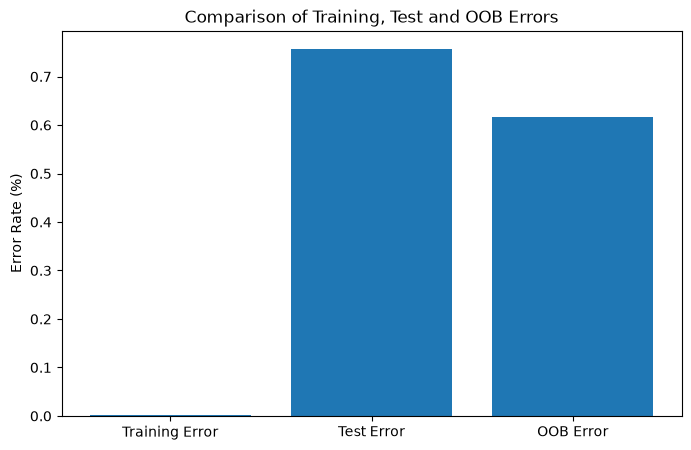

In [13]:
plt.figure(figsize=(8, 5))

plt.bar(
    error_comparison['Error Type'],
    error_comparison['Error Rate (%)']
)

plt.ylabel('Error Rate (%)')
plt.title('Comparison of Training, Test and OOB Errors')
plt.show()

### (c) Random forest without imbalance correction

100 trees, default settings, no class weights.

| | Train | Test |
|---|---:|---:|
| Misclassification | 0.002% | 0.756% |
| AUC | 1.000 | 0.993 |

Test confusion matrix: TN = 15,610, FP = 15, FN = 106, TP = 269. The OOB error is 0.617%, close to the 0.756% test error, so OOB is a reasonable stand-in for test error here. The training error is nearly zero because fully grown trees memorize the training data.

The low error is misleading, since 97.7% of the test set is negative anyway. Recall on the positive class is only 269/375 = 71.7%, and the 106 missed trucks are the costly mistakes (total cost = 10·15 + 500·106 = 53,150).

### (d) Research class imbalance in random forest

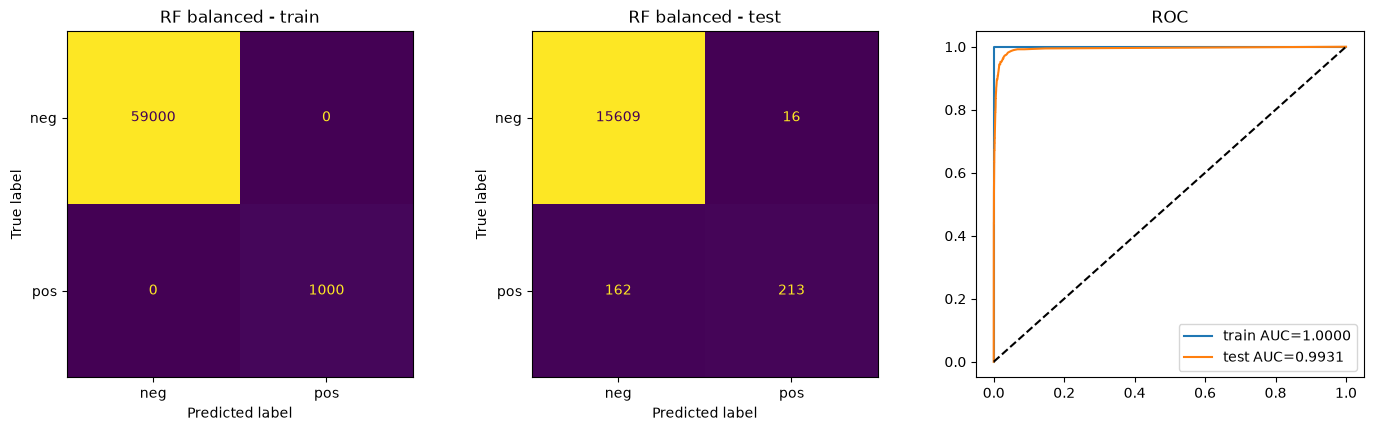

          error       AUC    FP     FN     cost
train  0.000000  1.000000   0.0    0.0      0.0
test   0.011125  0.993149  16.0  162.0  81160.0
OOB error: 0.0075666666666667215


E:\ANACONDA\Lib\site-packages\imblearn\ensemble\_forest.py:827: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


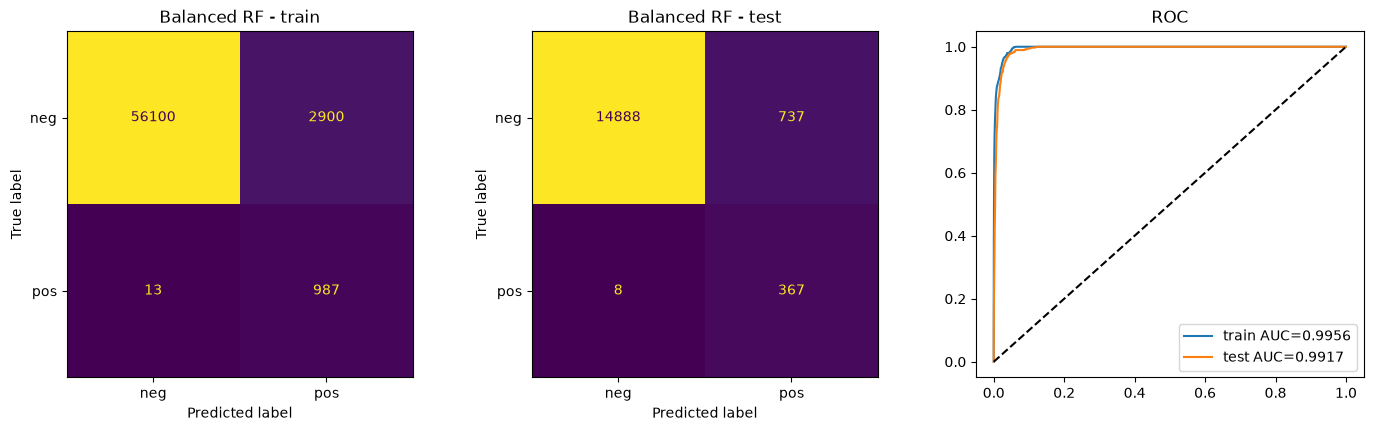

          error       AUC      FP    FN     cost
train  0.048550  0.995595  2900.0  13.0  35500.0
test   0.046562  0.991652   737.0   8.0  11370.0
OOB error: 0.029416666666666647


In [15]:
y_tr = (y_train == 'pos').astype(int); y_te = (y_test == 'pos').astype(int)

def evaluate(model, name, Xtr=X_train, ytr=y_tr):
    out = {}
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
    for i, (s, X, y) in enumerate([('train', Xtr, ytr), ('test', X_test, y_te)]):
        pred, prob = model.predict(X), model.predict_proba(X)[:, 1]
        cm = confusion_matrix(y, pred)
        ConfusionMatrixDisplay(cm, display_labels=['neg','pos']).plot(ax=ax[i], values_format='d', colorbar=False)
        ax[i].set_title(f'{name} - {s}')
        fpr, tpr, _ = roc_curve(y, prob)
        ax[2].plot(fpr, tpr, label=f'{s} AUC={roc_auc_score(y, prob):.4f}')
        out[s] = dict(error=1-accuracy_score(y, pred), AUC=roc_auc_score(y, prob),
                      FP=cm[0,1], FN=cm[1,0], cost=10*cm[0,1] + 500*cm[1,0])
    ax[2].plot([0,1],[0,1],'k--'); ax[2].legend(); ax[2].set_title('ROC'); plt.show()
    return pd.DataFrame(out).T

rf_bal = RandomForestClassifier(n_estimators=300, class_weight='balanced_subsample',
                                oob_score=True, n_jobs=-1, random_state=42).fit(X_train, y_tr)
print(evaluate(rf_bal, 'RF balanced')); print('OOB error:', 1 - rf_bal.oob_score_)
rf_brf = BalancedRandomForestClassifier(n_estimators=100, bootstrap=True, oob_score=True,
                                        random_state=42, n_jobs=-1).fit(X_train, y_tr)
print(evaluate(rf_brf, 'Balanced RF')); print('OOB error:', 1 - rf_brf.oob_score_)

### (d) Class imbalance in random forests

Common ways to handle imbalance in random forests: (1) class weights, which make errors on the minority class count more in the split criterion and in the leaf votes (`class_weight='balanced'` or `'balanced_subsample'`); (2) balanced bootstrap sampling, where each tree is grown on a sample with equal numbers of both classes, so the majority class is down-sampled per tree (Balanced Random Forest, or `sampsize` in R's randomForest); (3) over-sampling the minority class, e.g. SMOTE, before training; (4) moving the decision threshold below 0.5.

I tried (1) with `class_weight='balanced_subsample'` (300 trees) and (2) with a Balanced Random Forest (100 trees). Test results, compared with the plain forest from 1(c):

| Model | Test error | AUC | FP | FN | Recall | Total cost | OOB error |
|---|---:|---:|---:|---:|---:|---:|---:|
| RF, no correction (1c) | 0.756% | 0.9928 | 15 | 106 | 71.7% | 53,150 | 0.617% |
| RF, class weights | 1.113% | 0.9931 | 16 | 162 | 56.8% | 81,160 | 0.757% |
| Balanced RF | 4.656% | 0.9917 | 737 | 8 | 97.9% | 11,370 | 2.942% |

Class weights did not help: false negatives went from 106 to 162. The trees are grown to full depth and fit the training data almost perfectly, so reweighting the samples changes very little in how they split.

The balanced forest does what it is meant to do. It misses only 8 of the 375 failing trucks (recall 97.9%), at the price of 737 false alarms. Test error is much higher than before (0.76% → 4.66%), but a missed truck costs 500 and an unnecessary check costs 10, so the total cost drops from 53,150 to 11,370. AUC is almost the same for all three models, so their ranking of trucks is similar; the balanced forest mainly moves the operating point along the ROC curve.

For all three models the OOB error is below the test error. Part of the gap is probably the different class mix (2.34% positives in the test set vs 1.67% in the training set). For the balanced forest sklearn warned that some samples have no OOB score, so I treat its OOB value as approximate.

### (e) XGBoost and Model Trees

best alpha: {'reg_alpha': 0}
   param_reg_alpha  mean_test_score
0              0.0         0.989037
1              0.1         0.988740
2              1.0         0.988479
3             10.0         0.988964
4            100.0         0.980574
5-fold CV error: 0.0063833333333332964


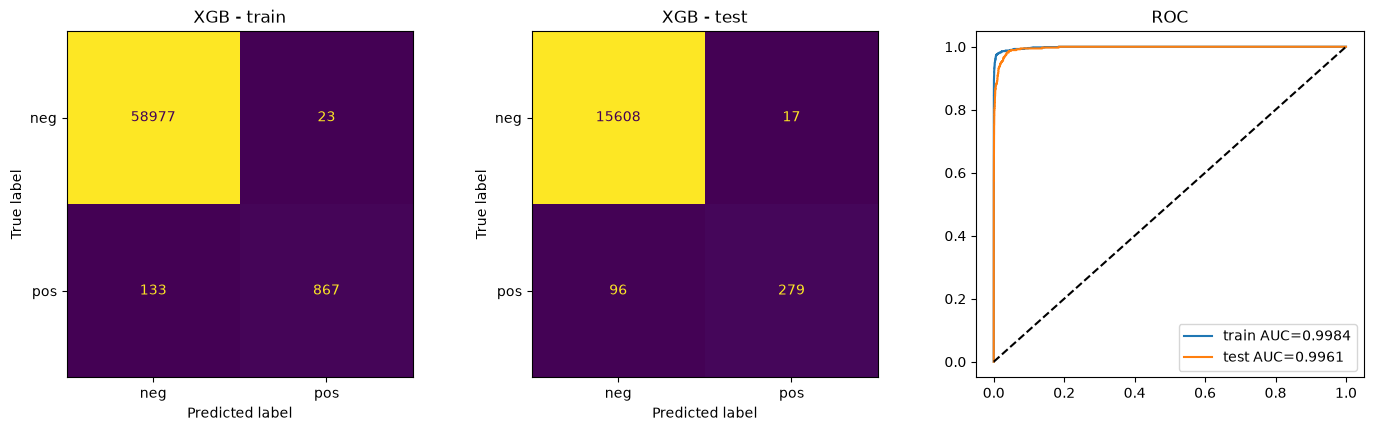

          error       AUC    FP     FN     cost
train  0.002600  0.998421  23.0  133.0  66730.0
test   0.007062  0.996071  17.0   96.0  48170.0


In [20]:
skf = StratifiedKFold(5, shuffle=True, random_state=42)
xgb = XGBClassifier(objective='binary:logistic', n_estimators=200, max_depth=3,
                    learning_rate=0.1, n_jobs=-1, random_state=42)
grid = GridSearchCV(xgb, {'reg_alpha': [0, 0.1, 1, 10, 100]}, scoring='roc_auc', cv=skf)
grid.fit(X_train, y_tr)
print('best alpha:', grid.best_params_)
print(pd.DataFrame(grid.cv_results_)[['param_reg_alpha', 'mean_test_score']])

best = grid.best_estimator_
cv_pred = cross_val_predict(best, X_train, y_tr, cv=skf)
print('5-fold CV error:', 1 - accuracy_score(y_tr, cv_pred))
print(evaluate(best, 'XGB'))

### (e) XGBoost with L1 regularization

I fit XGBoost (boosted trees, `binary:logistic`) and used its L1 penalty `reg_alpha` as the regularization term α. This is XGBoost's closest counterpart to the L1-penalized model in the question: it penalizes the leaf weights, not a logistic regression inside each node. α was chosen from {0, 0.1, 1, 10, 100} by 5-fold stratified cross-validation on the training set, using AUC. The best value was α = 0, so the L1 penalty did not improve the cross-validated AUC on this data.

The 5-fold CV error is 0.638% and the test error is 0.706%, so cross-validation gives an estimate close to the test error. The training error is 0.26%.

Test results: TN = 15,608, FP = 17, FN = 96, TP = 279, AUC = 0.9961 (training AUC 0.9984). Precision is 279/296 = 94.3% and recall is 279/375 = 74.4%.

Compared with the plain random forest from 1(c) (test error 0.756%, FN = 106, AUC 0.9928), XGBoost has a slightly lower error and a higher AUC. It still misses about a quarter of the failing trucks, because nothing has been done about the class imbalance yet (total cost 48,170 vs 53,150 for the random forest).

### (f) Use SMOTE to pre-process your data

best alpha: {'xgb__reg_alpha': 1}
5-fold CV error: 0.012950000000000017


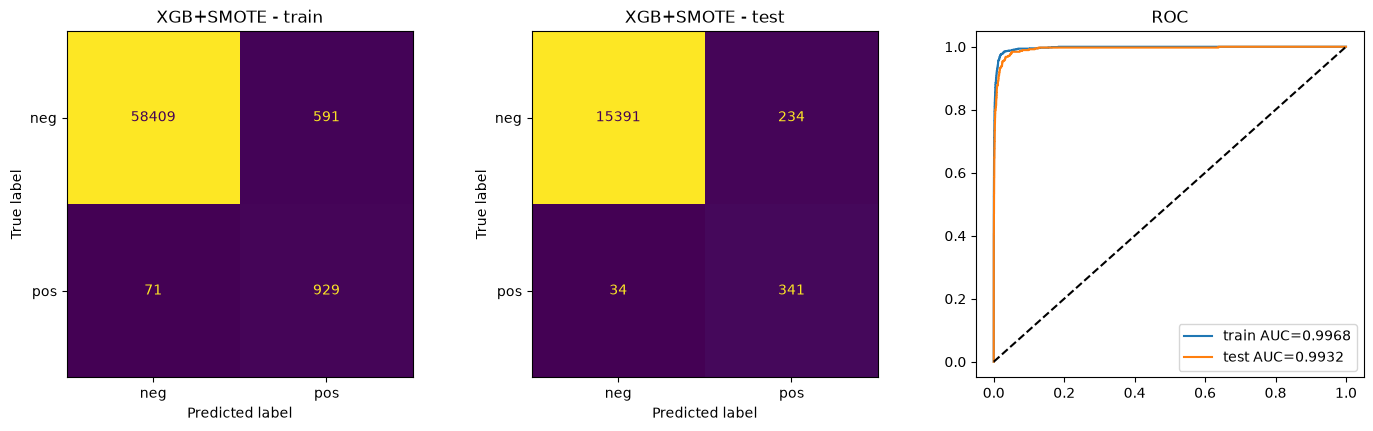

          error       AUC     FP    FN     cost
train  0.011033  0.996793  591.0  71.0  41410.0
test   0.016750  0.993184  234.0  34.0  19340.0


In [21]:
pipe = Pipeline([('smote', SMOTE(random_state=42)),
                 ('xgb', XGBClassifier(objective='binary:logistic', n_estimators=200,
                                       max_depth=3, learning_rate=0.1, n_jobs=-1, random_state=42))])
grid_s = GridSearchCV(pipe, {'xgb__reg_alpha': [0.01, 0.1, 1, 10, 100]}, scoring='roc_auc', cv=skf)
grid_s.fit(X_train, y_tr)
print('best alpha:', grid_s.best_params_)
cv_pred_s = cross_val_predict(grid_s.best_estimator_, X_train, y_tr, cv=skf)
print('5-fold CV error:', 1 - accuracy_score(y_tr, cv_pred_s))
print(evaluate(grid_s.best_estimator_, 'XGB+SMOTE'))

### (f) XGBoost with SMOTE

SMOTE is applied inside the cross-validation pipeline, so only the training folds are oversampled and every validation fold keeps the original class ratio. Oversampling the whole training set first and then cross-validating is the wrong way: synthetic points are interpolated from validation-fold positives, so the model effectively sees its validation data and the CV estimate becomes too optimistic. α was chosen from {0, 1, 10, 100} by 5-fold stratified CV (AUC), giving α = 1. The final model is fit on SMOTE of the full training set and evaluated on the untouched test set. The training row below is computed on the original (not oversampled) training data.

The 5-fold CV error is 1.295% and the test error is 1.675%. The two are of the same size, but the test error is a bit higher, partly because the test set has more positives (2.34% vs 1.67%), which are the harder class.

Test results: TN = 15,391, FP = 234, FN = 34, TP = 341, AUC = 0.9932 (training AUC 0.9968, training error 1.10%). Precision is 341/575 = 59.3% and recall is 341/375 = 90.9%.

| | Test error | AUC | FP | FN | Recall | Total cost |
|---|---:|---:|---:|---:|---:|---:|
| XGBoost, no SMOTE (1e) | 0.706% | 0.9961 | 17 | 96 | 74.4% | 48,170 |
| XGBoost + SMOTE (1f) | 1.675% | 0.9932 | 234 | 34 | 90.9% | 19,340 |

SMOTE cuts false negatives from 96 to 34 but raises false positives from 17 to 234. The test error goes up (0.71% → 1.68%) and AUC drops slightly (0.996 → 0.993), so by accuracy alone the uncompensated model looks better. Under the challenge cost (10 per false positive, 500 per false negative), the total cost falls from 48,170 to 19,340, so SMOTE is better in terms of total cost. Its recall is also higher than that of the plain random forest in 1(c) (71.7%), though it is below the balanced random forest in 1(d) (97.9%, cost 11,370).

## 2. ISLR 6.6.3

We estimate the regression coefficients by minimizing the RSS subject to the constraint $\sum_{j=1}^{p}|\beta_j| \le s$ (the lasso). As $s$ increases from 0, the constraint is relaxed and the model becomes more flexible.

**(a) Training RSS: (iv) Steadily decrease.**
At $s=0$ all coefficients are zero (the null model), which has the largest training RSS. As $s$ grows, the feasible set only gets larger, so the minimum RSS over it can never increase. It decreases until it reaches the ordinary least squares RSS.

**(b) Test RSS: (ii) Decrease initially, and then eventually start increasing in a U shape.**
For small $s$ the model is too restrictive and underfits (high bias), so test RSS is high. As $s$ increases, test RSS drops until the model reaches a good bias-variance balance. For large $s$ the model approaches least squares and begins to overfit, so test RSS rises again.

**(c) Variance: (iii) Steadily increase.**
A larger $s$ means a more flexible model whose coefficient estimates depend more on the particular training sample. At $s=0$ the model is constant (zero variance), and variance grows as $s$ grows.

**(d) Squared bias: (iv) Steadily decrease.**
A more flexible model fits the true relationship better, so bias decreases as $s$ increases.

**(e) Irreducible error: (v) Remain constant.**
The irreducible error $\mathrm{Var}(\epsilon)$ is a property of the data-generating process and does not depend on the model or on $s$.

## 3. ISLR 6.6.5

Setup: $n=2$, $p=2$, with $x_{11}=x_{12}$, $x_{21}=x_{22}$. The data are also centered: $x_{11}+x_{21}=0$, $x_{12}+x_{22}=0$ and $y_1+y_2=0$, so the intercept estimate is zero ($\hat\beta_0=0$).

Let $a = x_{11}=x_{12}$. Then $x_{21}=x_{22}=-a$.

**(a) Ridge regression optimization problem**

$$
\min_{\beta_1,\beta_2}\;
\left(y_1-\beta_1x_{11}-\beta_2x_{12}\right)^2
+\left(y_2-\beta_1x_{21}-\beta_2x_{22}\right)^2
+\lambda\left(\beta_1^2+\beta_2^2\right)
$$

**(b) Ridge estimates satisfy $\hat\beta_1=\hat\beta_2$**

Substituting $x_{11}=x_{12}=a$, $x_{21}=x_{22}=-a$ and $y_2=-y_1$, the objective becomes

$$
\left(y_1-(\beta_1+\beta_2)a\right)^2+\left(-y_1+(\beta_1+\beta_2)a\right)^2+\lambda(\beta_1^2+\beta_2^2)
= 2\left(y_1-(\beta_1+\beta_2)a\right)^2+\lambda(\beta_1^2+\beta_2^2).
$$

The first term depends on $\beta_1,\beta_2$ only through the sum $S=\beta_1+\beta_2$. For any fixed $S$, the penalty $\beta_1^2+\beta_2^2$ is minimized when $\beta_1=\beta_2=S/2$, since
$\beta_1^2+\beta_2^2=\tfrac{1}{2}S^2+\tfrac{1}{2}(\beta_1-\beta_2)^2$.
Hence the minimizer must have $\hat\beta_1=\hat\beta_2$.

**(c) Lasso optimization problem**

$$
\min_{\beta_1,\beta_2}\;
\left(y_1-\beta_1x_{11}-\beta_2x_{12}\right)^2
+\left(y_2-\beta_1x_{21}-\beta_2x_{22}\right)^2
+\lambda\left(|\beta_1|+|\beta_2|\right)
$$

**(d) Lasso solutions are not unique**

As in (b), the objective is
$2\left(y_1-(\beta_1+\beta_2)a\right)^2+\lambda(|\beta_1|+|\beta_2|)$.
The first term again depends only on $S=\beta_1+\beta_2$. For a fixed $S$, the penalty $|\beta_1|+|\beta_2|$ equals $|S|$ for **every** pair $(\beta_1,\beta_2)$ with the same sign (both $\ge 0$ or both $\le 0$), so the penalty does not distinguish between them. The optimal $S$ is therefore achieved along an entire line segment, not at a single point.

Writing $s$ for the optimal value of $|\beta_1+\beta_2|$, the lasso solutions are all points with

- $\hat\beta_1+\hat\beta_2=s$ and $\hat\beta_1,\hat\beta_2\ge 0$, or
- $\hat\beta_1+\hat\beta_2=-s$ and $\hat\beta_1,\hat\beta_2\le 0$.

Geometrically, the edge of the lasso constraint region $|\beta_1|+|\beta_2|\le s$ is parallel to the contour lines of the RSS (which are the lines $\beta_1+\beta_2=\text{const}$), so a whole edge of the diamond touches the optimal contour. Hence the lasso solution is not unique, whereas the ridge solution is unique with $\hat\beta_1=\hat\beta_2$.


## 4. ISLR 8.4.5

Ten bootstrapped samples give the following estimates of $P(\text{Class is Red}\mid X)$:

$$0.1,\;0.15,\;0.2,\;0.2,\;0.55,\;0.6,\;0.6,\;0.65,\;0.7,\;0.75$$

**Majority vote approach.**
Six of the ten estimates exceed 0.5 (0.55, 0.6, 0.6, 0.65, 0.7, 0.75), and four are below 0.5. Under majority vote, the final classification is **Red**.

**Average probability approach.**
The average probability is

$$
\frac{0.1+0.15+0.2+0.2+0.55+0.6+0.6+0.65+0.7+0.75}{10}=\frac{4.5}{10}=0.45 < 0.5,
$$

so the final classification is **Green**.

The two approaches disagree on the same data. Majority vote only counts which side of 0.5 each tree falls on, while averaging the probabilities also uses how confident each tree is. Here the "Green-leaning" trees are quite confident (0.1 to 0.2), which pulls the average below 0.5.

## 5. ISLR 9.7.3

The data (seven observations, $p=2$):

| Obs. | $X_1$ | $X_2$ | $Y$ |
|---|---|---|---|
| 1 | 3 | 4 | Red |
| 2 | 2 | 2 | Red |
| 3 | 4 | 4 | Red |
| 4 | 1 | 4 | Red |
| 5 | 2 | 1 | Blue |
| 6 | 4 | 3 | Blue |
| 7 | 4 | 1 | Blue |

**(a) Sketch.**
See the plot below. The Red points lie in the upper-left region and the Blue points in the lower-right region.

**(b) Optimal separating hyperplane.**
The maximal margin hyperplane lies midway between the closest opposite-class pairs, $(2,2)$ vs $(2,1)$ and $(4,4)$ vs $(4,3)$. It passes through the midpoints $(2,1.5)$ and $(4,3.5)$, so its slope is 1 and its equation is

$$X_2 = X_1 - 0.5 \quad\Longleftrightarrow\quad 0.5 - X_1 + X_2 = 0 .$$

**(c) Classification rule.**
Classify to **Red** if $\beta_0+\beta_1X_1+\beta_2X_2 > 0$, and to **Blue** otherwise, with

$$\beta_0 = 0.5,\qquad \beta_1=-1,\qquad \beta_2=1 .$$

For example, $(1,4)$ gives $0.5-1+4=3.5>0$ (Red) and $(2,1)$ gives $0.5-2+1=-0.5<0$ (Blue).

**(d) Margin.**
The margin is the perpendicular distance from the hyperplane to the closest observations, e.g. the point $(2,2)$:

$$
M=\frac{|0.5-2+2|}{\sqrt{(-1)^2+1^2}}=\frac{0.5}{\sqrt2}\approx 0.354 .
$$

The two margin lines are parallel to the hyperplane, at distance $0.354$ on each side: $X_2=X_1$ (through observations 2 and 3) and $X_2=X_1-1$ (through observations 5 and 6).

**(e) Support vectors.**
The support vectors are observations 2, 3, 5 and 6, i.e. $(2,2)$, $(4,4)$, $(2,1)$ and $(4,3)$.

**(f) Effect of moving observation 7.**
Observation 7, $(4,1)$, is not a support vector: it lies strictly outside the margin. The maximal margin hyperplane depends only on the support vectors, so a slight movement of observation 7 (one that keeps it outside the margin) would not change the hyperplane.

**(g) A separating hyperplane that is not optimal.**
For example,

$$0.3 - X_1 + X_2 = 0 \quad (X_2 = X_1 - 0.3),$$

i.e. $\beta_0=0.3$, $\beta_1=-1$, $\beta_2=1$. It still separates the classes: all Red points give a positive value (e.g. $(2,2)\to 0.3>0$, $(4,4)\to0.3>0$) and all Blue points give a negative value (e.g. $(2,1)\to-0.7<0$, $(4,3)\to-0.7<0$). However, it passes closer to the Red points than the optimal hyperplane, so its margin is smaller.

**(h) Adding a point so the classes are no longer separable.**
Add a Blue observation at $(2,3)$. It lies on the Red side of any line that separates the original points (the optimal line gives $0.5-2+3=1.5>0$), and it is surrounded by Red points, so no hyperplane can separate the two classes any more.

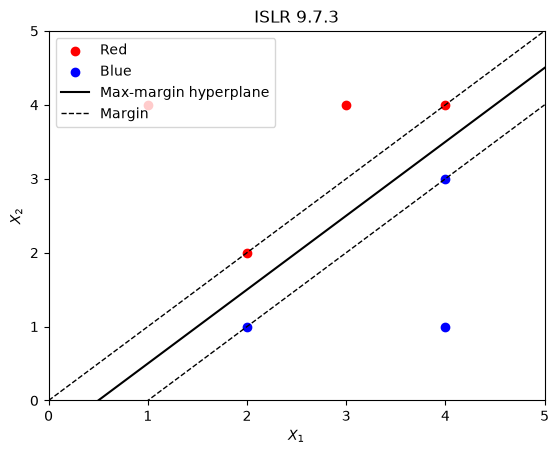

In [19]:
red  = np.array([[3,4],[2,2],[4,4],[1,4]])
blue = np.array([[2,1],[4,3],[4,1]])
x = np.linspace(0, 5, 100)
plt.scatter(*red.T, c='red', label='Red'); plt.scatter(*blue.T, c='blue', label='Blue')
plt.plot(x, x-0.5, 'k-', label='Max-margin hyperplane')
plt.plot(x, x, 'k--', lw=1); plt.plot(x, x-1, 'k--', lw=1, label='Margin')
plt.xlim(0, 5); plt.ylim(0, 5); plt.xlabel('$X_1$'); plt.ylabel('$X_2$')
plt.legend(); plt.title('ISLR 9.7.3'); plt.show()